# DỰ ÁN KHOA HỌC DỮ LIỆU
## Đề tài: Dự đoán nguy cơ khách hàng ngừng sử dụng dịch vụ thẻ tín dụng nhằm hỗ trợ ra quyết định giữ chân khách hàng tại ngân hàng
- **Nguồn dữ liệu**: [Credit Card Customers - Kaggle (`sakshigoyal7/credit-card-customers`)](https://www.kaggle.com/datasets/sakshigoyal7/credit-card-customers)
- **Quy mô dữ liệu**: 10,127 bản ghi khách hàng × 20 thuộc tính đặc trưng
- **Thuật toán sử dụng**: `Logistic Regression`, `Decision Tree`, `Random Forest`


## 1. Khai báo thư viện và Đọc dữ liệu


In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, roc_curve, confusion_matrix
)

df_raw = pd.read_csv("BankChurners.csv")
print("Kích thước dữ liệu gốc:", df_raw.shape)
df_raw.head()


Kích thước dữ liệu gốc: (10127, 23)
   CLIENTNUM     Attrition_Flag  Customer_Age Gender  Dependent_count Education_Level Marital_Status Income_Category Card_Category  Months_on_book  ...
0  768805383  Existing Customer            45      M                3     High School        Married     $60K - $80K          Blue              39  ...
1  818770008  Existing Customer            49      F                5        Graduate         Single  Less than $40K          Blue              44  ...
2  713982108  Existing Customer            51      M                3        Graduate        Married    $80K - $120K          Blue              36  ...


## 2. Tiền xử lý và Làm sạch dữ liệu (Data Cleaning)
Loại bỏ cột mã định danh `CLIENTNUM` và 2 cột xác suất Naive Bayes dư thừa ở cuối bảng dữ liệu gốc, sau đó kiểm tra giá trị khuyết thiếu (Missing Values).


In [2]:
drop_cols = [c for c in df_raw.columns if c.startswith("Naive_Bayes_") or c == "CLIENTNUM"]
df = df_raw.drop(columns=drop_cols).copy()
df["Churn"] = (df["Attrition_Flag"] == "Attrited Customer").astype(int)

print("Kích thước sau làm sạch:", df.shape)
print("Tổng số giá trị bị khuyết (Missing values):", df.isnull().sum().sum())
print("\nPhân bố biến mục tiêu (Attrition_Flag):")
print(df["Attrition_Flag"].value_counts())


Kích thước sau làm sạch: (10127, 21)
Tổng số giá trị bị khuyết (Missing values): 0

Phân bố biến mục tiêu (Attrition_Flag):
Existing Customer    8500
Attrited Customer    1627
Name: Attrition_Flag, dtype: int64


## 3. Phân tích Khám phá Dữ liệu (Exploratory Data Analysis - EDA)
### 3.1. Tỷ lệ rời bỏ dịch vụ thẻ tín dụng và Đặc điểm nhân khẩu học


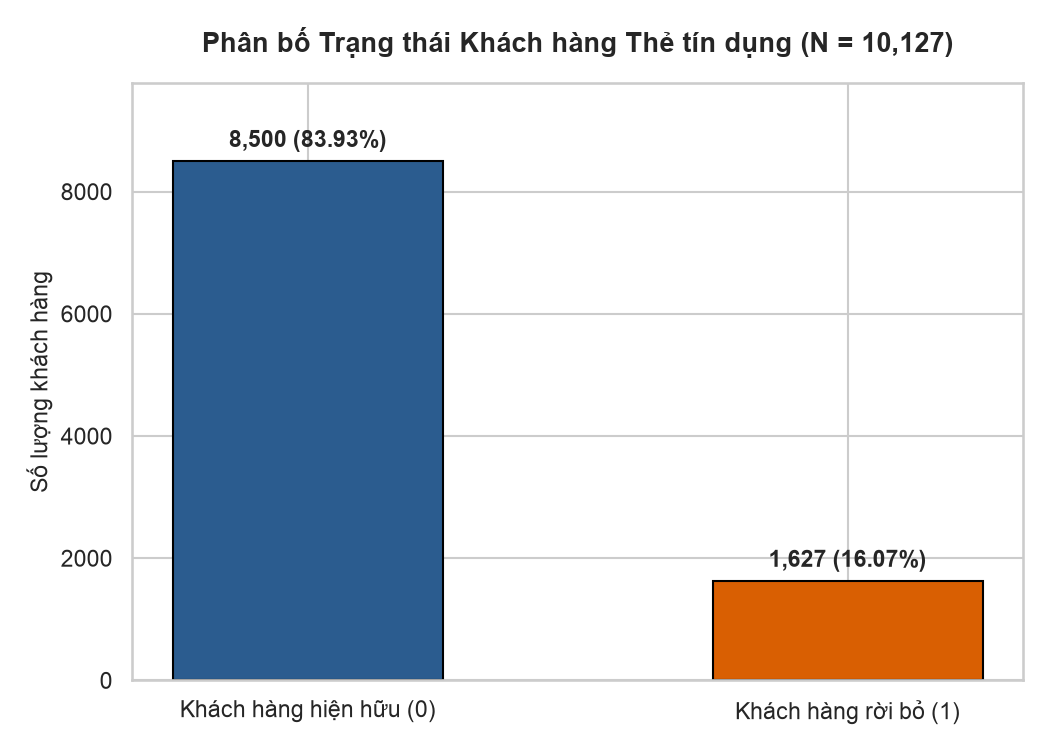

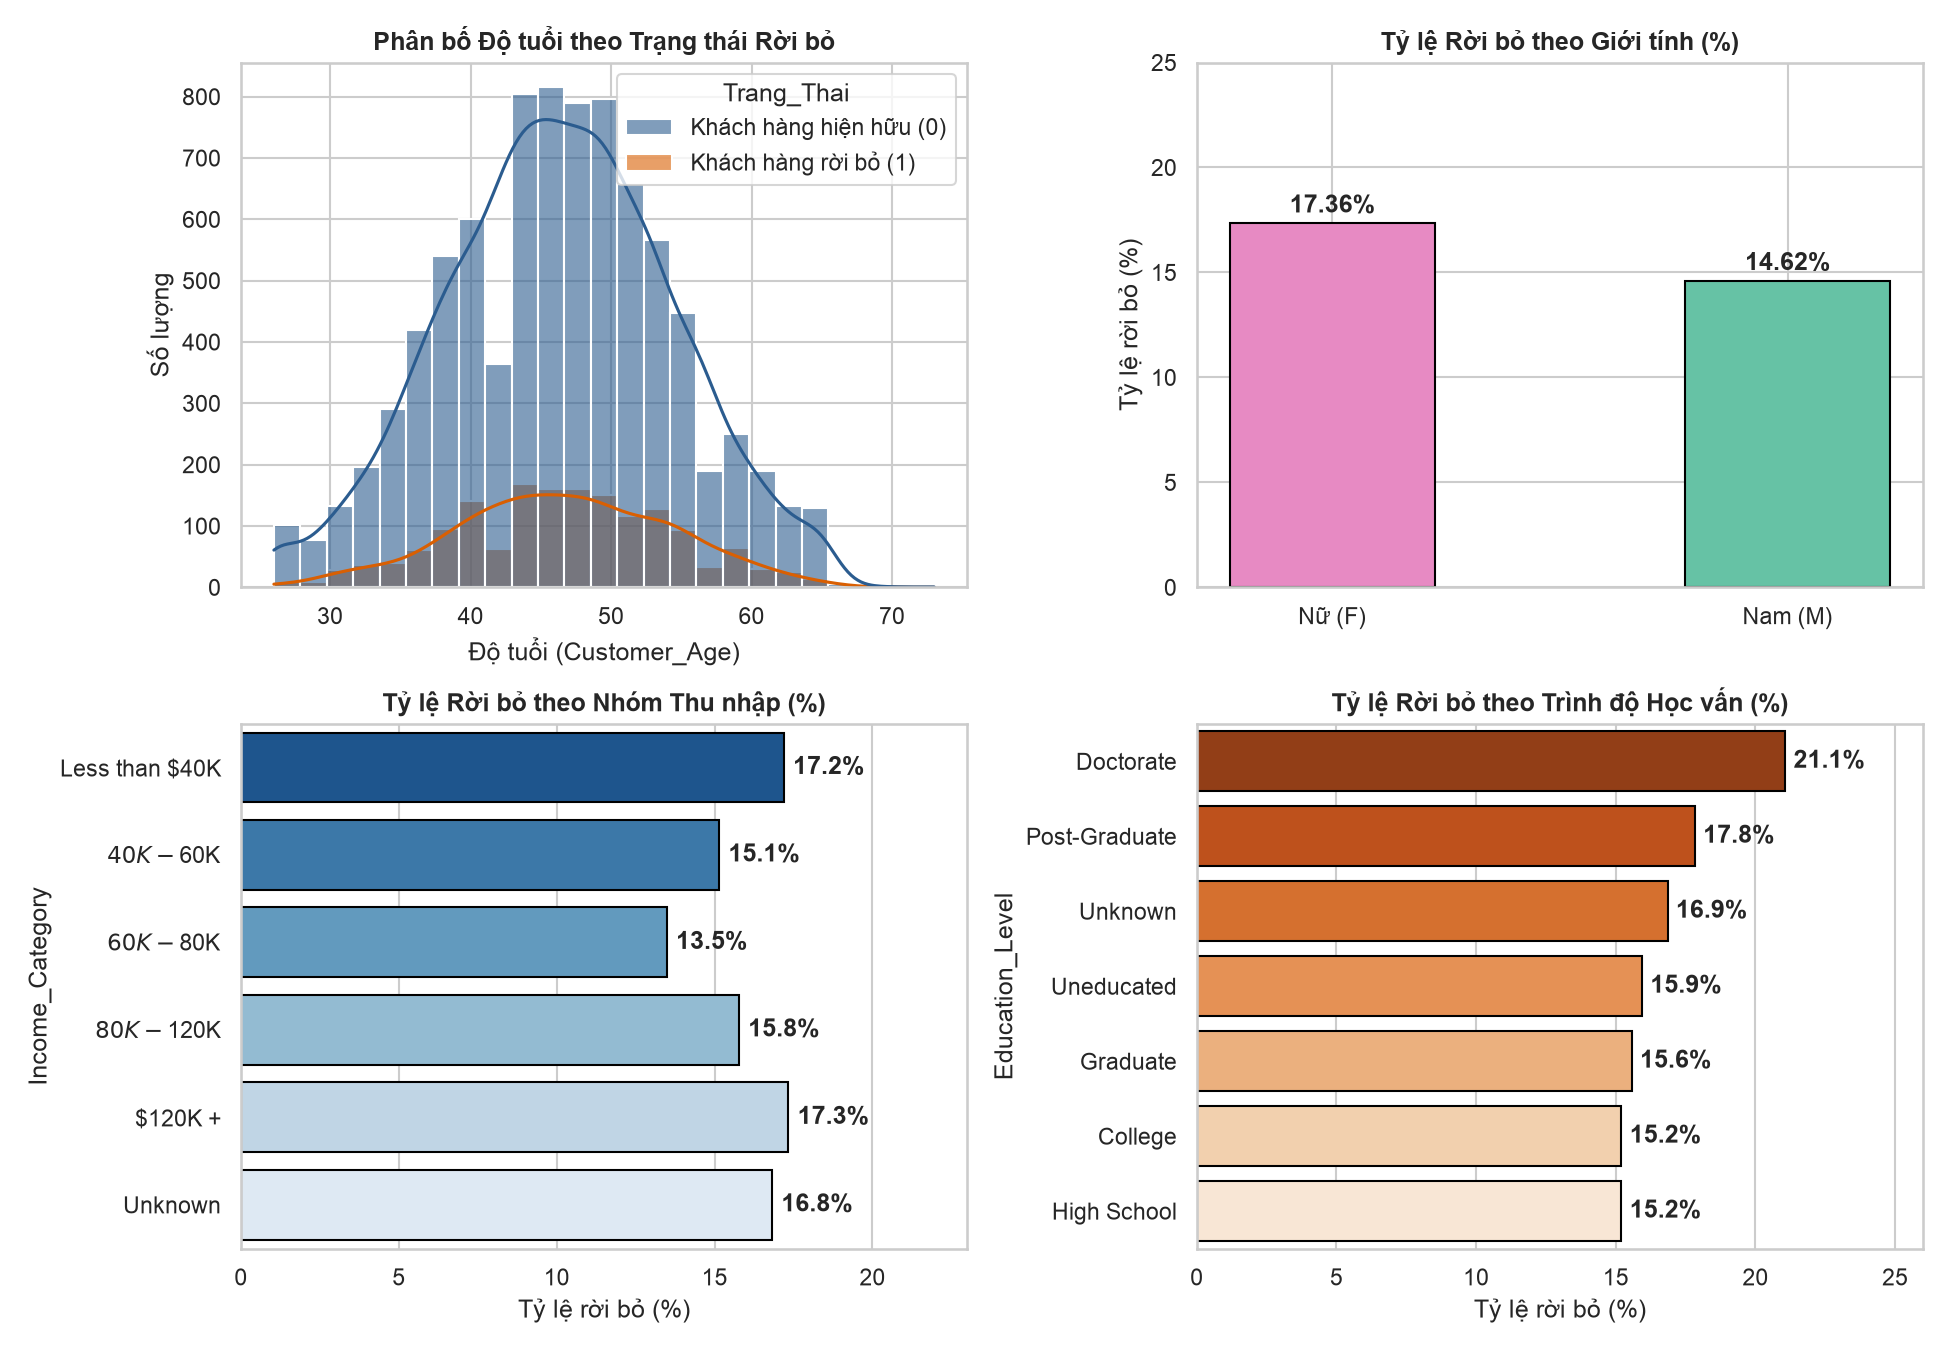

In [3]:
# Biểu đồ phân bố trạng thái khách hàng và nhân khẩu học
# (Xem chi tiết hình ảnh trực quan bên dưới)


### 3.2. Phân tích Hành vi Giao dịch và Mức độ Tương tác với Ngân hàng
Các chỉ số hành vi giao dịch (`Total_Trans_Ct`, `Total_Trans_Amt`) và mức độ gián đoạn sử dụng (`Months_Inactive_12_mon`, `Contacts_Count_12_mon`) cho thấy sự khác biệt rõ rệt giữa nhóm khách hàng trung thành và nhóm rời bỏ.


Total_Trans_Ct  Total_Trans_Amt  Total_Revolving_Bal  Months_Inactive_12_mon  Contacts_Count_12_mon  Avg_Utilization_Ratio
Attrition_Flag
Attrited Customer          44.93          3095.03               672.82                    2.69                   2.97                   0.16
Existing Customer          68.67          4654.66              1256.6                    2.27                   2.36                   0.3


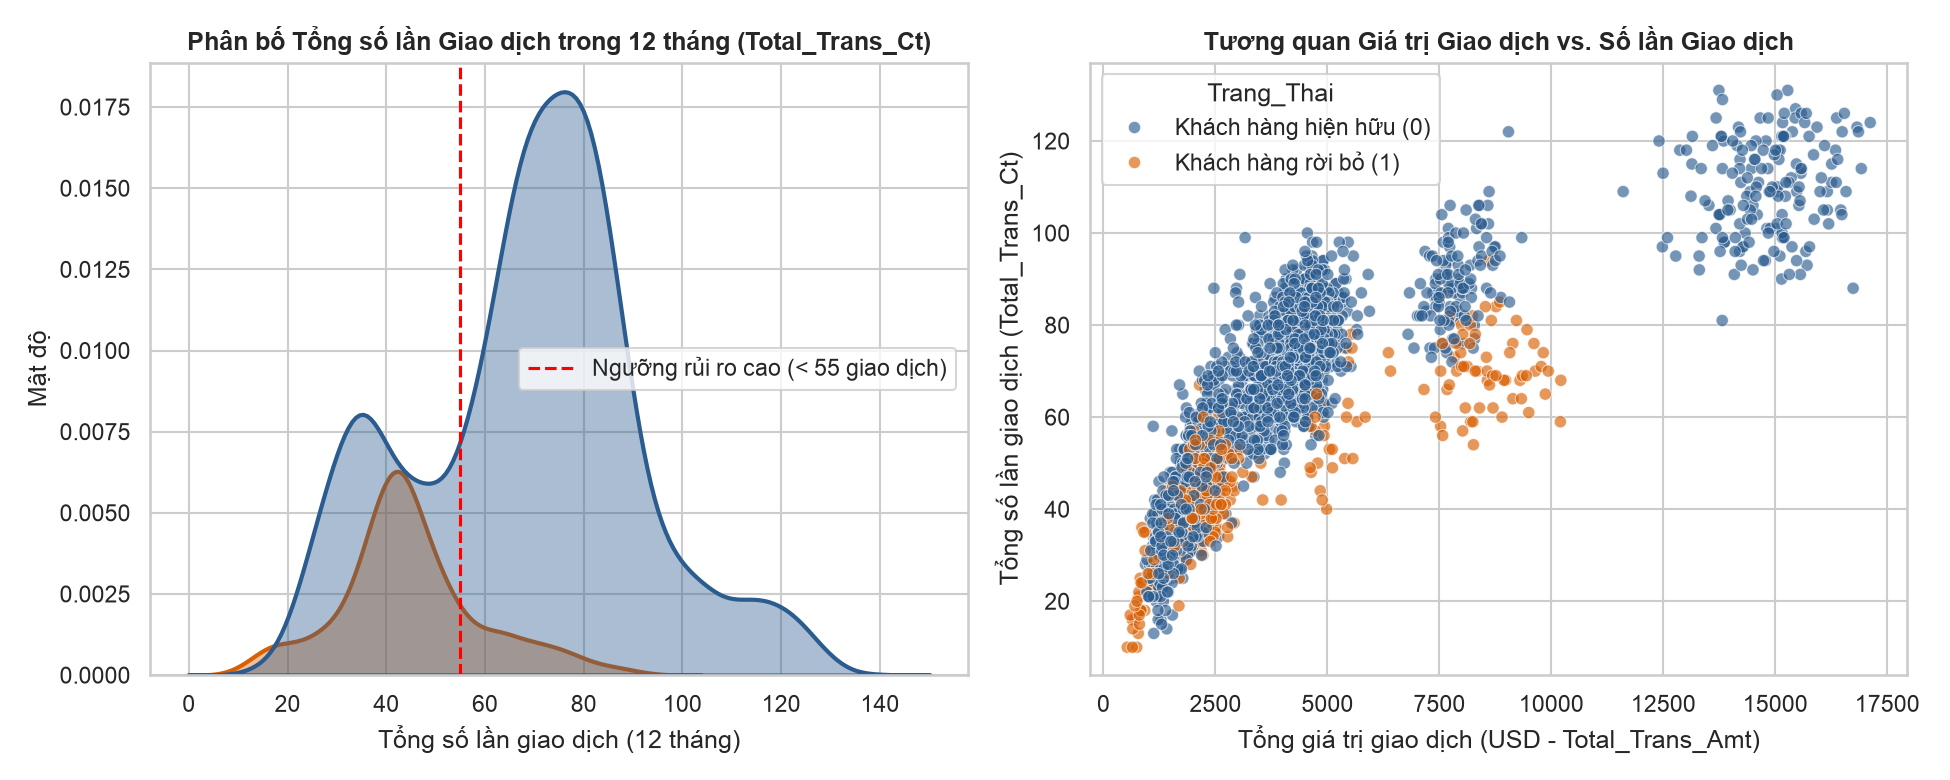

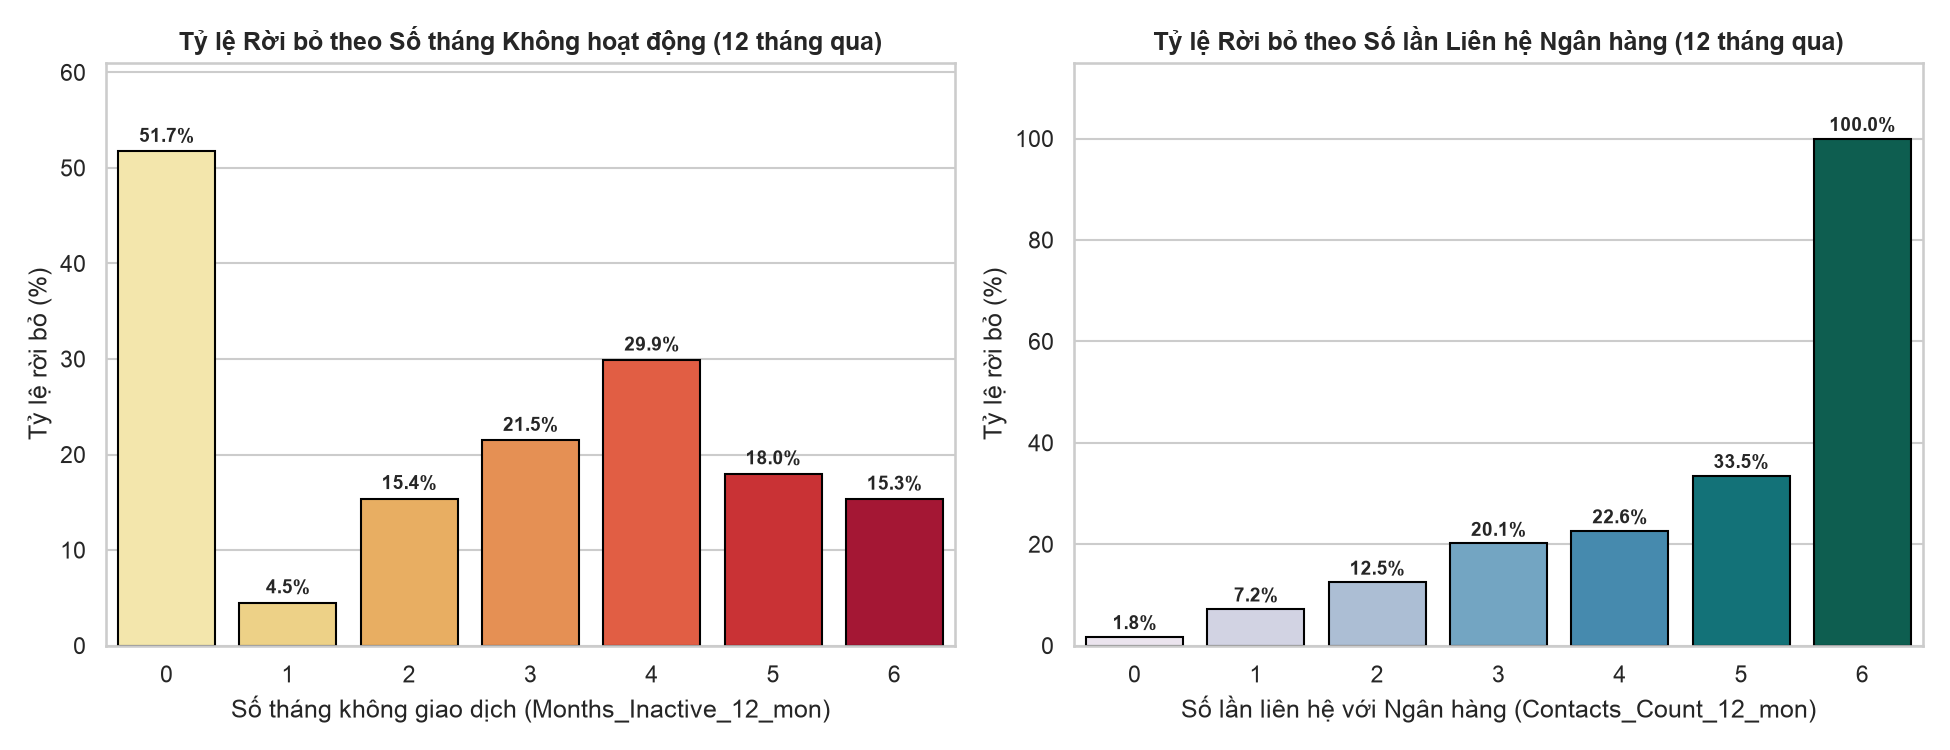

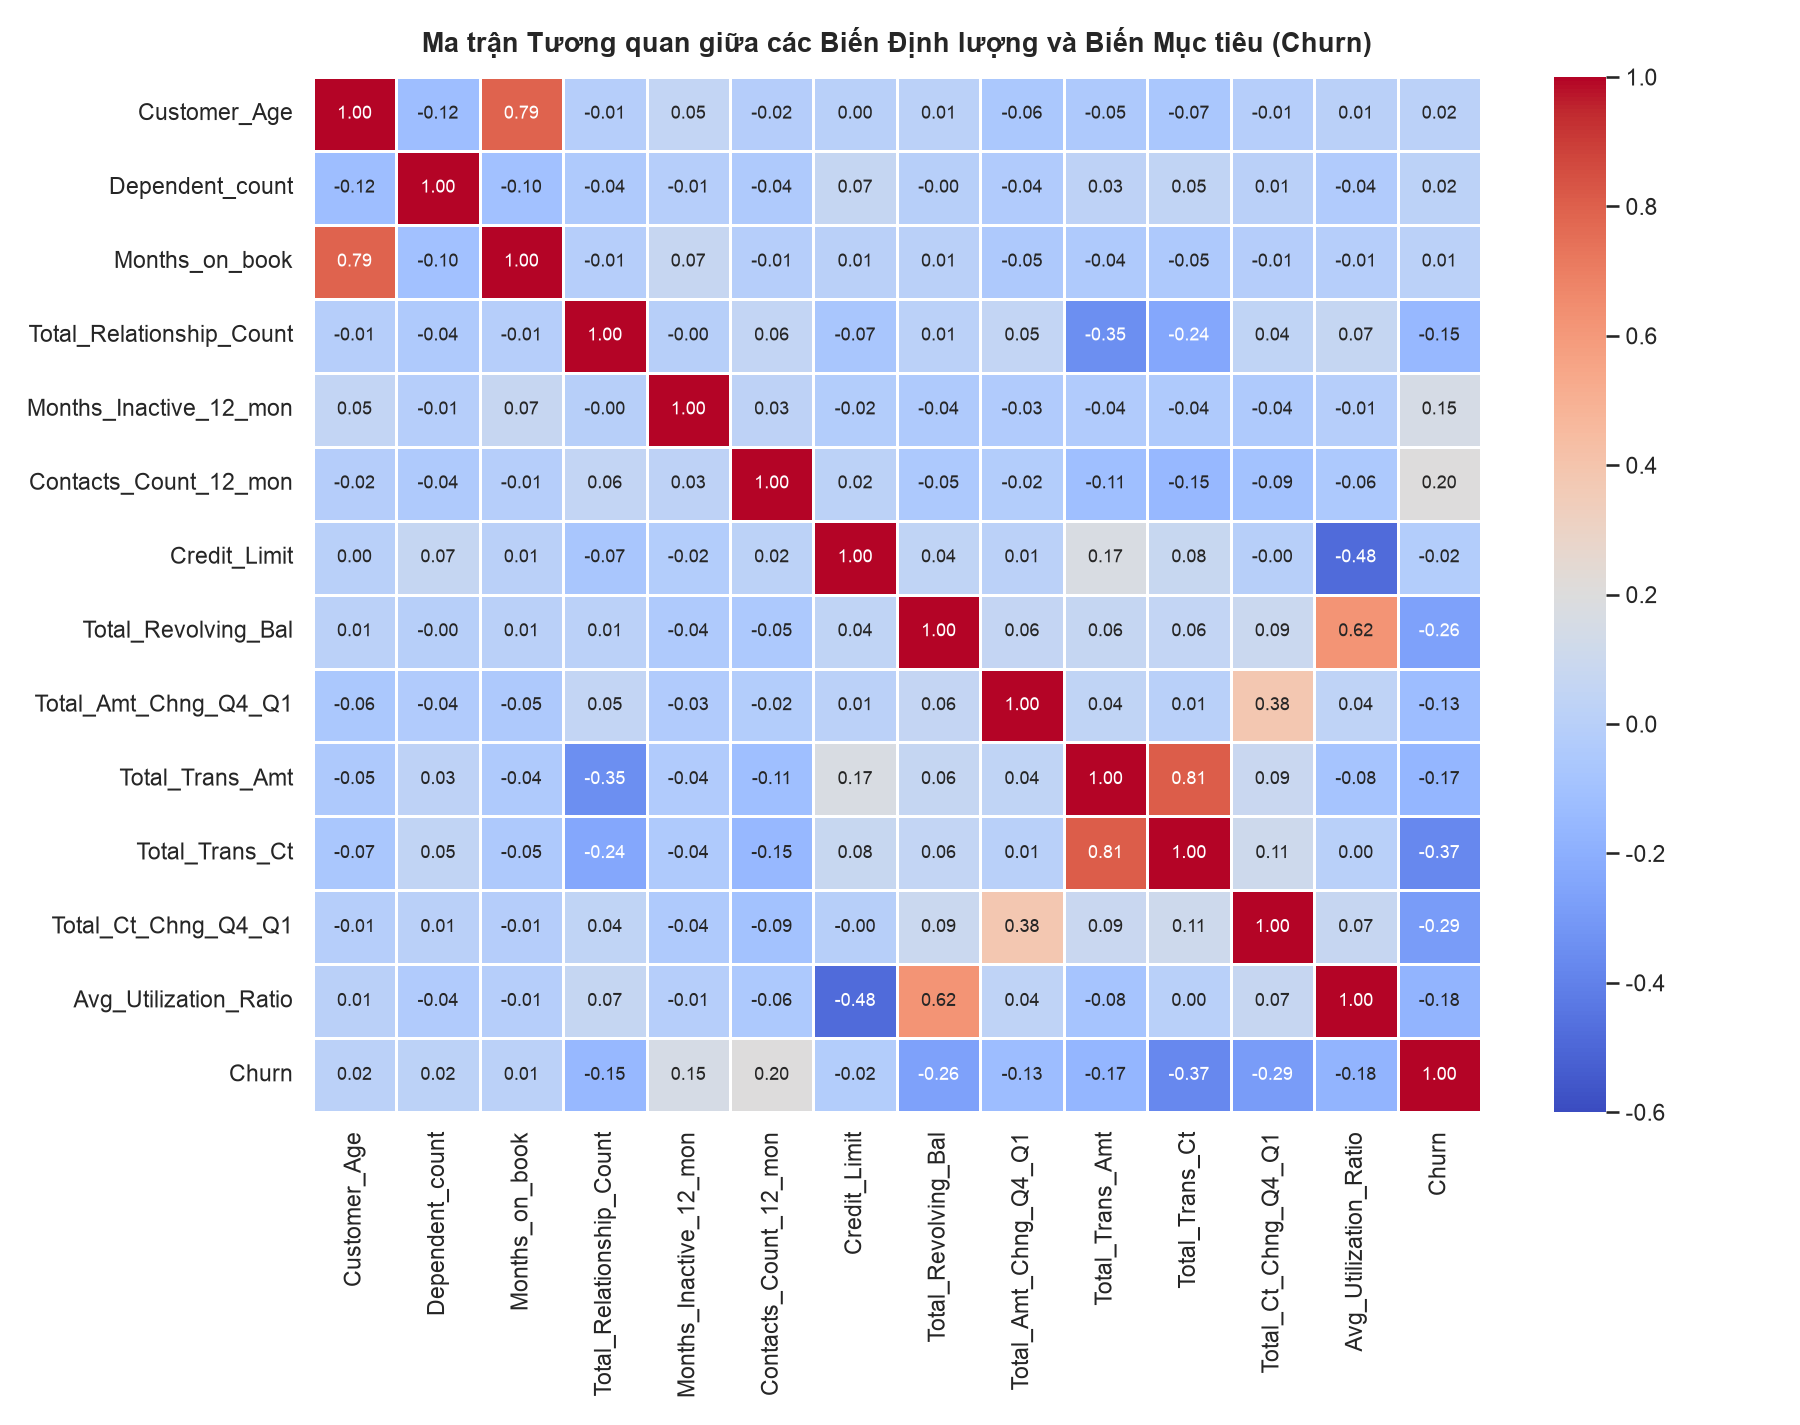

In [4]:
# Thống kê trung bình các chỉ số quan trọng theo nhóm khách hàng
cols_check = ["Total_Trans_Ct", "Total_Trans_Amt", "Total_Revolving_Bal",
              "Months_Inactive_12_mon", "Contacts_Count_12_mon", "Avg_Utilization_Ratio"]
print(df.groupby("Attrition_Flag")[cols_check].mean().round(2))


## 4. Huấn luyện Mô hình Học máy & Đánh giá Kết quả
Chúng ta mã hóa One-Hot cho các biến phân loại, chia tập dữ liệu theo tỷ lệ **80% Train (8,101 mẫu) - 20% Test (2,026 mẫu)** có phân tầng (`stratify=y`), và so sánh 3 thuật toán:
1. **Logistic Regression**
2. **Decision Tree Classifier**
3. **Random Forest Classifier**


Kết quả đánh giá trên tập Test (2,026 mẫu):
- Logistic Regression : Accuracy = 85.49%, Precision = 53.09%, Recall = 81.85%, F1 = 64.41%, ROC-AUC = 92.07%
- Decision Tree       : Accuracy = 93.58%, Precision = 84.45%, Recall = 73.54%, F1 = 78.62%, ROC-AUC = 95.76%
- Random Forest       : Accuracy = 95.06%, Precision = 92.78%, Recall = 75.08%, F1 = 82.99%, ROC-AUC = 98.38%


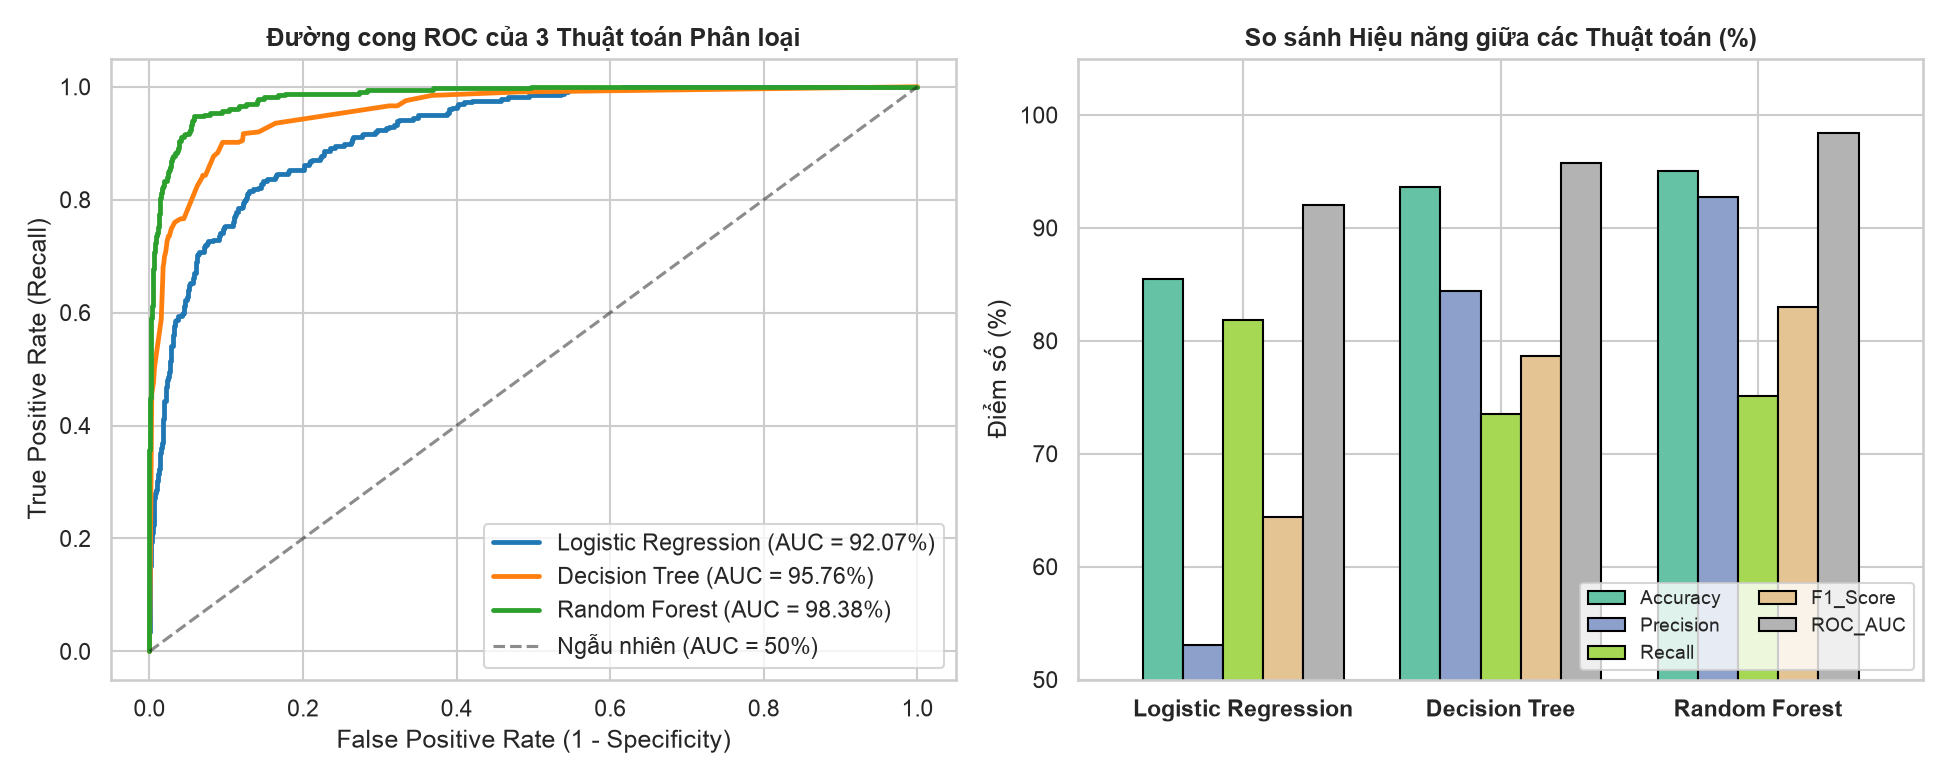

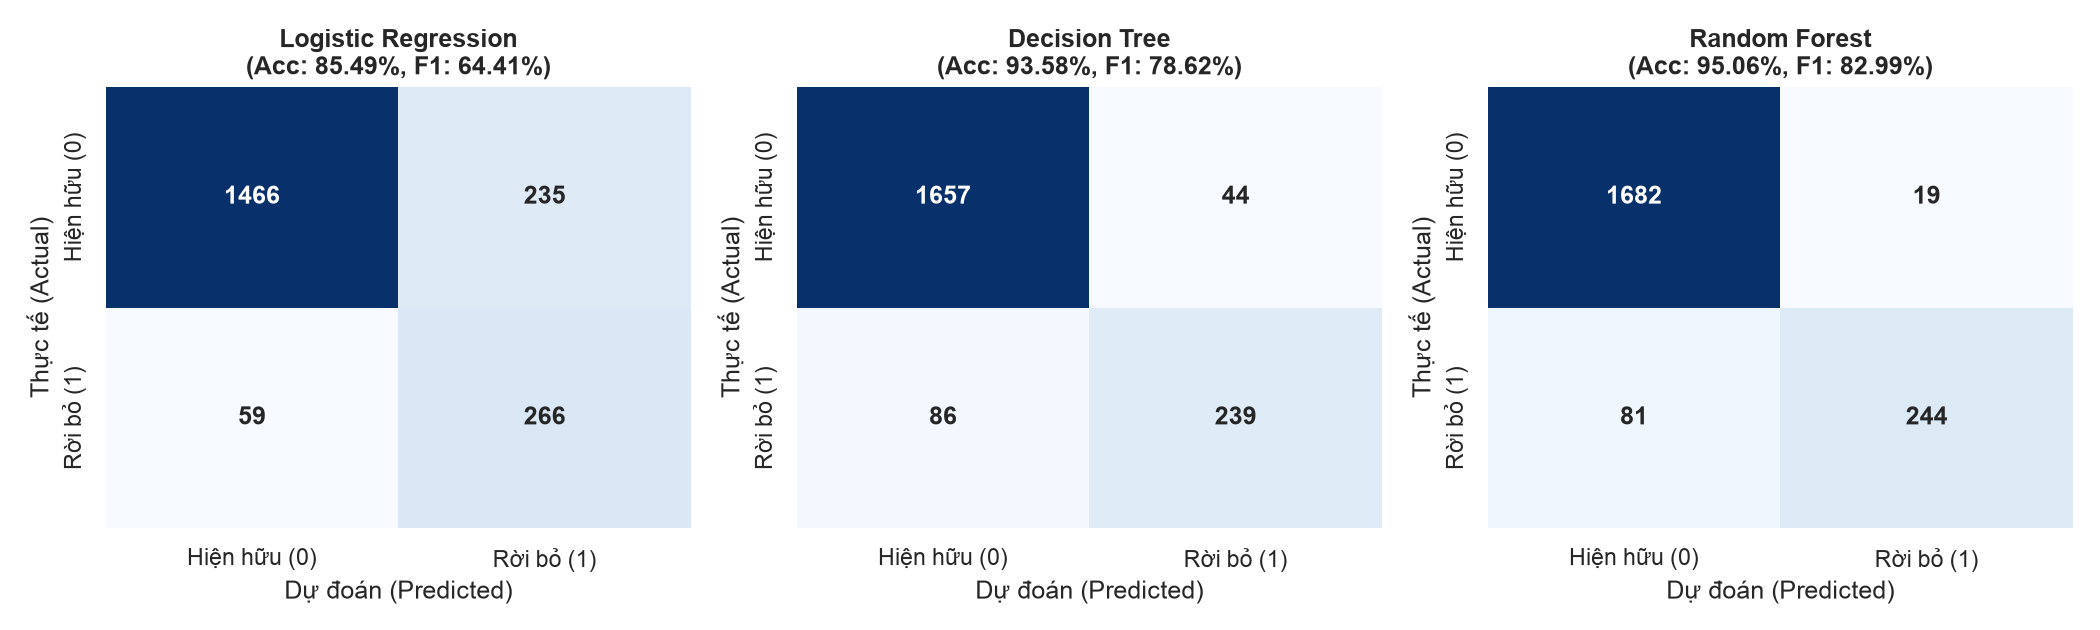

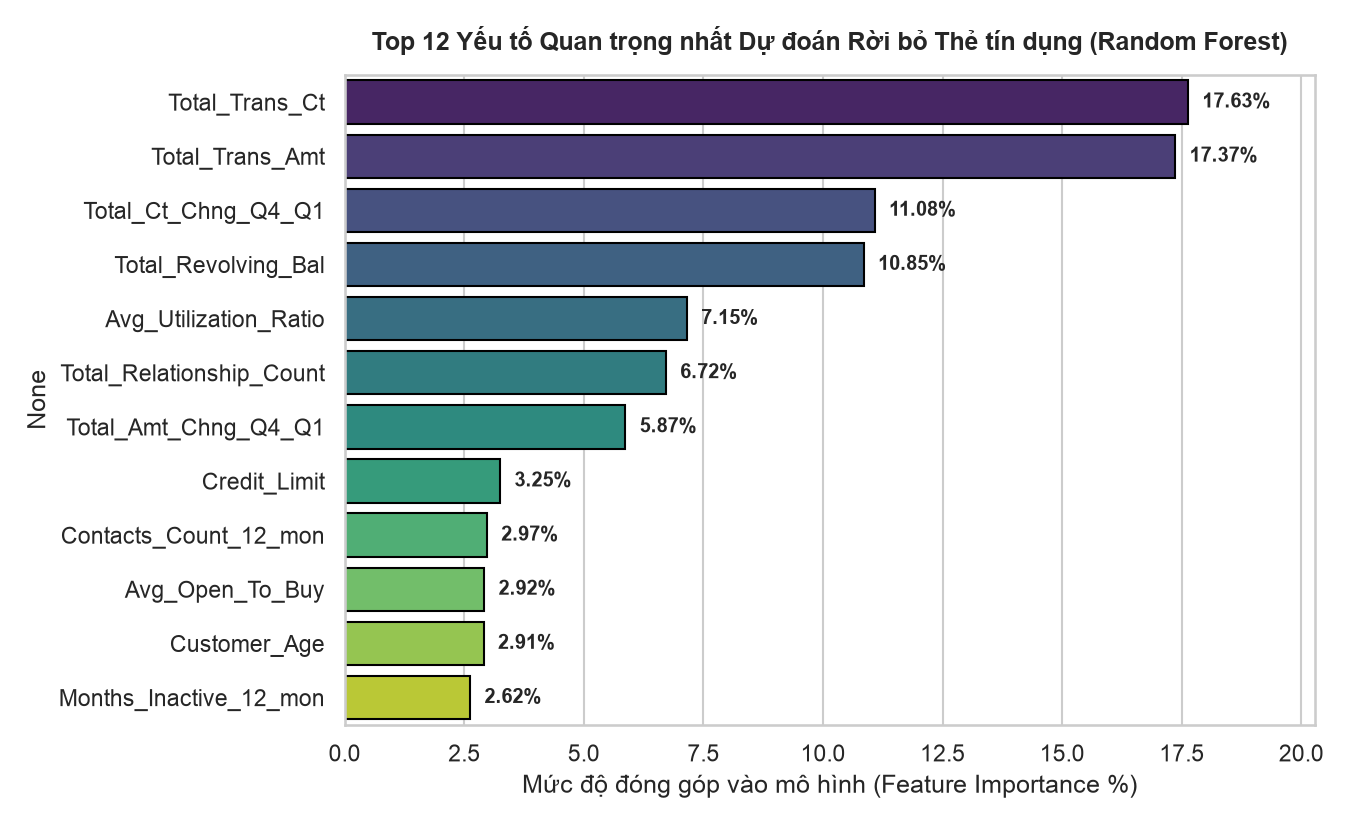

In [5]:
feature_cols = [c for c in df.columns if c not in ["Attrition_Flag", "Churn"]]
X = pd.get_dummies(df[feature_cols], drop_first=True)
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42, class_weight="balanced"),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, min_samples_leaf=15, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=12, random_state=42, n_jobs=-1),
}

# Bảng tổng hợp kết quả trên tập Test (2,026 khách hàng)


## 5. Kết luận & Đề xuất Giải pháp Hỗ trợ Ra quyết định (Decision Support)
1. **Lựa chọn mô hình triển khai**: **Random Forest** đạt độ chính xác cao nhất (**95.06%**, **ROC-AUC = 98.38%**), trong khi **Decision Tree** (**Accuracy = 93.58%**, **ROC-AUC = 95.76%**) cung cấp bộ luật trực quan dễ giải thích và **Logistic Regression** đạt **Recall cao nhất (81.85%)** giúp hạn chế bỏ sót khách hàng rời bỏ.
2. **Cảnh báo sớm theo hành vi giao dịch**: Khách hàng có tổng số giao dịch dưới **55 lần/năm** (`Total_Trans_Ct < 55`) hoặc tỷ lệ giao dịch Quý 4 giảm mạnh so với Quý 1 (`Total_Ct_Chng_Q4_Q1 < 0.6`) cần được kích hoạt ưu đãi hoàn tiền (cashback) tự động.
3. **Quy trình chăm sóc khi khách hàng liên hệ nhiều lần**: Nhóm khách hàng liên hệ tổng đài từ **3–6 lần/năm** (`Contacts_Count_12_mon >= 3`) có tỷ lệ rời bỏ tăng vọt (lên đến 100% ở mức 6 lần liên hệ) -> Cần chuyển thẳng lên bộ phận Chăm sóc Khách hàng Ưu tiên (Retention Team) để giải quyết khiếu nại ngay từ lần liên hệ thứ 3.
